# Avance 1: Diseño del estudio y relaciones entre variables

**Proyecto:** ¿Qué se asocia a las hospitalizaciones prolongadas? Egresos FONASA, Chile 2020
**Tema:** Determinantes de hospitalizaciones prolongadas (egresos hospitalarios, MINSAL / FONASA)

1. Pregunta de investigación e hipótesis
2. Revisión de literatura
3. Metodología
4. Diagrama metodológico
5. Análisis de relaciones entre variables

## 1. Pregunta de investigación

### Contexto

Los días que un paciente pasa hospitalizado determinan cuántas camas se ocupan y cuánto cuesta la atención. Unas pocas hospitalizaciones muy largas concentran buena parte de las camas: en los egresos FONASA de 2020, las estadías de más de 15 días fueron el 9,4 % de los egresos, pero usaron el 47,1 % de los días-cama (sección 5). Saber qué características se asocian a esas estadías ayuda a planificar camas y a anticipar qué pacientes necesitarán más recursos.

### Pregunta

> **¿Qué factores clínicos, demográficos y del sistema de salud se asocian con la duración de la estadía hospitalaria y con las estadías prolongadas (más de 15 días) en los egresos de beneficiarios FONASA en Chile durante 2020?**

Una estadía es **prolongada** si dura más de 15 días, que es el percentil 90 de los días de estada de estos egresos.

### Hipótesis

- **H₀:** la duración de la estadía y la estadía prolongada son independientes de los factores clínicos, demográficos y del sistema de salud.
- **H₁:** al menos uno de esos factores se asocia a la duración de la estadía o a la estadía prolongada.

La hipótesis se divide en tres grupos de factores:

| Hipótesis | Factores | H₁ específica |
|---|---|---|
| H1a | Clínicos: capítulo CIE-10, cirugía | Se asocian a la duración y a la estadía prolongada |
| H1b | Demográficos: edad, sexo, nacionalidad, etnia | Se asocian a la duración y a la estadía prolongada (se espera más días a mayor edad) |
| H1c | Del sistema de salud: tipo de establecimiento, región | Se asocian a la duración y a la estadía prolongada |

Con casi un millón de egresos, cualquier diferencia mínima sale significativa. Por eso cada prueba se juzga también por su **tamaño de efecto**: un factor se considera relevante si su efecto es al menos pequeño según Cohen (1988).

## 2. Revisión de literatura

**El diagnóstico explica parte de la duración, pero no toda.** Los Grupos Relacionados por el Diagnóstico (GRD) agrupan pacientes con diagnósticos y procedimientos parecidos porque consumen recursos parecidos, y se construyeron usando la duración de la estadía (Fetter et al., 1980). Freitas et al. (2012), con nueve millones de hospitalizaciones en Portugal, muestran que incluso dentro de un mismo GRD la edad, el tipo de ingreso y el tipo de hospital seguían asociados a las estadías extremas. Esas estadías eran el 3,9 % de los casos y sumaban el 19,2 % de los días de hospitalización. Por eso este proyecto combina variables clínicas con variables del paciente y del establecimiento.

**Cómo se modela la estadía.** En la revisión de Lequertier et al. (2021), la regresión fue el método más usado para predecir la duración de la estadía (64,9 % de los estudios). Esto respalda usar regresión múltiple, que además permite ver el efecto de cada factor manteniendo los demás constantes.

**Muestras grandes.** Con bases administrativas de cientos de miles de registros casi todo resulta significativo. Lin et al. (2013) recomiendan informar el tamaño del efecto junto al valor-p, y aquí se interpreta con los umbrales de Cohen (1988).

### Gap

En Chile, los estudios con datos públicos de egresos se han concentrado en grupos específicos. Olivares-Tirado (2020) estudió a personas de 60 años o más con egresos DEIS de 2017 y encontró que el 1 % de sus egresos fueron estadías de 60 días o más con baja necesidad médica, que ocuparon el 15 % de los días-cama. No encontramos un análisis que evalúe en conjunto factores clínicos, demográficos y del sistema de salud sobre la estadía prolongada en el total de egresos FONASA, ni en 2020, el primer año de la pandemia. Este proyecto aborda ese vacío.

## 3. Metodología

### Tipo de análisis

- **Descriptivo:** cómo se distribuyen los días de estada y las estadías prolongadas.
- **Inferencial:** pruebas de hipótesis entre cada factor y las variables respuesta (sección 5).
- **Predictivo (Avance 2):** regresiones múltiples que estiman el efecto de todos los factores a la vez.

### Fuente, unidad de análisis y período

| Aspecto | Detalle |
|---|---|
| Fuente | DEIS-MINSAL, datos abiertos de egresos hospitalarios 2020 (https://repositoriodeis.minsal.cl/DatosAbiertos/EGRESOS/) |
| Registros | 1.330.477 egresos; 968.495 de FONASA. Se excluyen 397 con más de 365 días de estada (errores de registro). **Quedan 968.098**, dentro del rango exigido (700.000 a 1.000.000) |
| Unidad de análisis | Cada egreso hospitalario |
| Período | 1 de enero al 31 de diciembre de 2020 |

### Variables seleccionadas

**Cómo se eligieron.** La base trae 18 columnas. Se usaron tres criterios: (1) que la variable se conozca **al momento de la hospitalización**, para que sirva para predecir; (2) que tenga un motivo, ya sea de la literatura o del funcionamiento del sistema de salud, para afectar la duración, y (3) que no repita información de otra columna. Así quedan 2 variables respuesta y 8 factores.

| Variable | Columna original | Tipo | Por qué se incluye |
|---|---|---|---|
| **Días de estada** | `DIAS_ESTADA` | Numérica (conteo) | Variable respuesta de la regresión lineal |
| **Estadía prolongada** | `DIAS_ESTADA` > 15 | Categórica (Sí / No) | Variable respuesta de la regresión logística |
| Capítulo CIE-10 | `DIAG1` agrupado con el diccionario DEIS | Categórica (21) | Aproxima la complejidad clínica, ya que la base no trae el peso GRD (Fetter et al., 1980) |
| Cirugía | `INTERV_Q` | Categórica (Sí / No) | Separa hospitalizaciones quirúrgicas de médicas |
| Edad | `GRUPO_EDAD` | Numérica (punto medio del tramo) y ordinal (11 tramos) | A mayor edad, estadías más largas (Freitas et al., 2012) |
| Sexo | `SEXO` | Categórica (Hombre / Mujer) | Variable demográfica básica |
| Nacionalidad | `GLOSA_PAIS_ORIGEN` | Categórica (Chilena / Extranjera) | Permite ver diferencias en grupos con distinto acceso a salud |
| Etnia | `ETNIA` | Categórica (Sí / No) | Igual que la nacionalidad: posible inequidad |
| Tipo de establecimiento | `PERTENENCIA_ESTABLECIMIENTO_SALUD` | Categórica (Público SNSS / No SNSS) | El tipo de hospital se asocia a estadías extremas (Freitas et al., 2012) |
| Región de residencia | `REGION_RESIDENCIA` | Categórica (16) | La oferta de camas y especialistas cambia entre regiones |

**Columnas que no se usan:** `DIAG2` (causa externa) parecía útil, pero al revisarla solo se registra cuando el diagnóstico principal es un traumatismo (capítulo S-T), así que repite información del capítulo CIE-10; `CONDICION_EGRESO` (vivo o fallecido) se conoce recién al final de la hospitalización, así que no sirve para predecirla; `PROCED` no está descrita en el diccionario del DEIS; la comuna tiene 344 categorías y la región resume esa información; previsión y año son constantes después del filtro, y las columnas `GLOSA_` repiten a sus códigos.

### Modelos propuestos (se ajustan en el Avance 2)

| Modelo | Variable respuesta | Por qué |
|---|---|---|
| Regresión lineal múltiple | log(días de estada + 1) | Estima cuánto cambia la duración con cada factor, manteniendo los demás constantes. Se usa el logaritmo porque los días tienen una cola larga a la derecha (sección 5.1) |
| Regresión logística múltiple | Estadía prolongada (Sí / No) | Estima cómo cambia la probabilidad de una estadía prolongada con cada factor (razones de odds) |

Las variables categóricas entran como variables indicadoras (*dummies*). Antes de ajustar se revisa que los predictores no estén demasiado asociados entre sí (sección 5.4 y VIF en el Avance 2).

### Métricas de evaluación

Se separa un 70 % de los datos para entrenar y un 30 % para evaluar.

- **Regresión lineal:** R² ajustado, MAE y RMSE.
- **Regresión logística:** AUC-ROC, sensibilidad, precisión, F1 y matriz de confusión. Como solo el 9,4 % de los egresos son prolongados, la exactitud (*accuracy*) por sí sola engañaría: un modelo que diga siempre "No" acertaría el 90,6 % de las veces.

### Limitaciones

La base abierta no trae el peso GRD, el hospital, la fecha de ingreso ni los diagnósticos secundarios, y la edad viene en tramos de 10 años. Además, 2020 fue un año atípico por la pandemia.

## 4. Diagrama metodológico

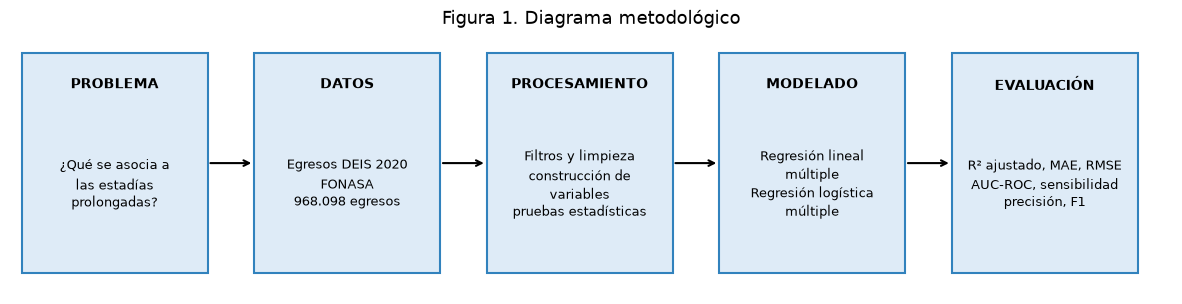

In [1]:
import matplotlib.pyplot as plt

etapas = [("Problema", "¿Qué se asocia a\nlas estadías\nprolongadas?"),
          ("Datos", "Egresos DEIS 2020\nFONASA\n968.098 egresos"),
          ("Procesamiento", "Filtros y limpieza\nconstrucción de\nvariables\npruebas estadísticas"),
          ("Modelado", "Regresión lineal\nmúltiple\nRegresión logística\nmúltiple"),
          ("Evaluación", "R² ajustado, MAE, RMSE\nAUC-ROC, sensibilidad\nprecisión, F1")]
fig, ax = plt.subplots(figsize=(15, 3.4))
ax.set_xlim(0, 5); ax.set_ylim(0, 1); ax.axis("off")
for i, (etapa, detalle) in enumerate(etapas):
    ax.add_patch(plt.Rectangle((i + 0.05, 0.08), 0.8, 0.84, fc="#deebf7", ec="#3182bd", lw=1.5))
    ax.text(i + 0.45, 0.80, etapa.upper(), ha="center", va="center", fontweight="bold")
    ax.text(i + 0.45, 0.42, detalle, ha="center", va="center", fontsize=9.5, linespacing=1.4)
    if i < len(etapas) - 1:
        ax.annotate("", xy=(i + 1.05, 0.5), xytext=(i + 0.85, 0.5), arrowprops=dict(arrowstyle="->", lw=1.5))
ax.set_title("Figura 1. Diagrama metodológico", fontsize=13)
plt.show()

## 5. Análisis de relaciones entre variables

### Carga de datos y construcción de las variables

El notebook lee directamente el archivo `data/raw/EGRESOS_2020.zip` y aplica los filtros de la sección 3.

In [2]:
import warnings
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.stats.diagnostic import lilliefors
from statsmodels.stats.multitest import multipletests

warnings.filterwarnings("ignore")
ALPHA = 0.05
rng = np.random.default_rng(2026)
DATA = Path("data/raw")
AZUL, GRIS = "#2a78d6", "#c9c8c3"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "axes.grid.axis": "y", "axes.axisbelow": True, "grid.color": "#e5e4e0"})
FUENTE = "Fuente: elaboración propia con datos de egresos hospitalarios DEIS-MINSAL, 2020."

def fuente(fig):
    fig.text(0.01, 0, FUENTE, fontsize=9, style="italic", va="top")

def num(x, decimales=0):
    """Número en formato chileno: 968.098 / 0,413."""
    return f"{x:,.{decimales}f}".translate(str.maketrans(",.", ".,"))

def miles(n):
    return num(n)

def valor_p(p):
    return "< 0,001" if p < 0.001 else num(p, 3)

def decision(p):
    return "Se rechaza H0" if p < ALPHA else "No se rechaza H0"

with zipfile.ZipFile(DATA / "EGRESOS_2020.zip") as z:
    df = pd.read_csv(z.open("EGRE_DATOS_ABIERTOS_2020.csv"), sep=";", encoding="cp1252", dtype=str)
print("Egresos 2020:           ", miles(len(df)))
df = df[df["PREVISION"] == "1"].copy()  # solo FONASA
print("Egresos FONASA:         ", miles(len(df)))
df["dias_estada"] = pd.to_numeric(df["DIAS_ESTADA"])
df = df[df["dias_estada"] <= 365].copy()  # más de un año = error de registro
print("Con estada de hasta 365:", miles(len(df)))

Egresos 2020:            1.330.477


Egresos FONASA:          968.495


Con estada de hasta 365: 968.098


In [3]:
EDAD_MEDIA = {"menor de un año": 0.5, "1 a 9": 5, "10 a 19": 14.5, "20 a 29": 24.5, "30 a 39": 34.5,
              "40 a 49": 44.5, "50 a 59": 54.5, "60 a 69": 64.5, "70 a 79": 74.5, "80 a 89": 84.5,
              "90 y más": 92.5}
REGION = {"01": "Tarapacá", "02": "Antofagasta", "03": "Atacama", "04": "Coquimbo", "05": "Valparaíso",
          "06": "O'Higgins", "07": "Maule", "08": "Biobío", "09": "Araucanía", "10": "Los Lagos",
          "11": "Aysén", "12": "Magallanes", "13": "Metropolitana", "14": "Los Ríos",
          "15": "Arica y Parinacota", "16": "Ñuble"}
cie = pd.read_excel(DATA / "x2020/Diccionario BD egresos hospitalario.xlsx", "codigo CIE-10", header=8)
cie.columns = cie.columns.str.strip()
CAPITULO = {"A00-B99": "Infecciosas (A-B)", "C00-D48": "Tumores (C-D)", "D50-D89": "Sangre (D)",
            "E00-E90": "Endocrinas (E)", "F00-F99": "Mentales (F)", "G00-G99": "Sist. nervioso (G)",
            "H00-H59": "Ojo (H)", "H60-H95": "Oído (H)", "I00-I99": "Circulatorias (I)",
            "J00-J99": "Respiratorias (J)", "K00-K93": "Digestivas (K)", "L00-L99": "Piel (L)",
            "M00-M99": "Osteomusculares (M)", "N00-N99": "Genitourinarias (N)", "O00-O99": "Embarazo y parto (O)",
            "P00-P96": "Perinatales (P)", "Q00-Q99": "Congénitas (Q)", "R00-R99": "Síntomas (R)",
            "S00-T98": "Traumatismos (S-T)", "V01-Y98": "Causas externas (V-Y)", "Z00-Z99": "Controles (Z)",
            "U00-U99": "COVID-19 (U)"}

# Variables respuesta
df["prolongada"] = np.where(df["dias_estada"] > 15, "Sí", "No")
# Factores clínicos
df["capitulo"] = (df["DIAG1"].map(dict(zip(cie["CODIGO SUBCATEGORIA"], cie["CAPITULO"])))
                  .fillna(df["DIAG1"].str[:3].map(dict(zip(cie["CODIGO CATEGORIA"], cie["CAPITULO"]))))
                  .map(CAPITULO))
df["cirugia"] = df["INTERV_Q"].map({"1": "Sí", "2": "No"})
# Factores demográficos
df["edad"] = df["GRUPO_EDAD"].map(EDAD_MEDIA)
df["tramo_edad"] = pd.Categorical(df["GRUPO_EDAD"], categories=list(EDAD_MEDIA), ordered=True)
df["sexo"] = df["SEXO"].str.capitalize()
df["nacionalidad"] = df["GLOSA_PAIS_ORIGEN"].map({"Chileno": "Chilena", "extranjero": "Extranjera"})
df["etnia"] = np.where(df["ETNIA"].str.startswith("Si"), "Sí", "No")
# Factores del sistema de salud
df["establecimiento"] = np.where(df["PERTENENCIA_ESTABLECIMIENTO_SALUD"].str.startswith("Pert"),
                                 "Público (SNSS)", "No SNSS")
df["region"] = df["REGION_RESIDENCIA"].map(REGION)

VARIABLES = ["dias_estada", "prolongada", "edad", "tramo_edad", "sexo", "nacionalidad", "etnia",
             "capitulo", "cirugia", "establecimiento", "region"]
print("Valores faltantes en las variables:", int(df[VARIABLES].isna().sum().sum()))
larga = df["prolongada"] == "Sí"
print(f"Días de estada: media {num(df['dias_estada'].mean(), 1)} | mediana {num(df['dias_estada'].median())} | "
      f"percentil 90 {num(df['dias_estada'].quantile(0.9))}")
print(f"Estadías prolongadas: {num(100 * larga.mean(), 1)} % de los egresos y "
      f"{num(100 * df.loc[larga, 'dias_estada'].sum() / df['dias_estada'].sum(), 1)} % de los días-cama")
print(f"Egresos con causa externa (DIAG2) fuera del capítulo de traumatismos: "
      f"{((df['DIAG2'].notna()) & (df['capitulo'] != 'Traumatismos (S-T)')).sum()}")
df[VARIABLES].head()

Valores faltantes en las variables: 0
Días de estada: media 6,7 | mediana 3 | percentil 90 15
Estadías prolongadas: 9,4 % de los egresos y 47,1 % de los días-cama
Egresos con causa externa (DIAG2) fuera del capítulo de traumatismos: 74


,dias_estada,prolongada,edad,tramo_edad,sexo,nacionalidad,etnia,capitulo,cirugia,establecimiento,region
0,1,No,5.0,1 a 9,Hombre,Chilena,No,Congénitas (Q),Sí,No SNSS,Tarapacá
1,1,No,5.0,1 a 9,Hombre,Chilena,No,Congénitas (Q),Sí,No SNSS,Tarapacá
2,1,No,5.0,1 a 9,Hombre,Chilena,No,Controles (Z),Sí,No SNSS,Tarapacá
3,1,No,5.0,1 a 9,Hombre,Chilena,No,Genitourinarias (N),Sí,No SNSS,Tarapacá
4,1,No,5.0,1 a 9,Hombre,Chilena,No,Genitourinarias (N),Sí,No SNSS,Tarapacá


**Cómo se reporta cada prueba.** Para cada prueba se indican H₀ y H₁, el estadístico, el valor-p, α = 0,05, la decisión y un tamaño de efecto. Con n ≈ 968.000 los valores-p suelen ser tan pequeños que se informan como "< 0,001". Los umbrales de Cohen (1988) para leer el efecto son:

| Medida | Pequeño | Mediano | Grande |
|---|---|---|---|
| ρ de Spearman, r biserial, V de Cramér | 0,1 | 0,3 | 0,5 |
| ε² (Kruskal-Wallis) | 0,01 | 0,06 | 0,14 |

### 5.1 Pruebas de normalidad

Las variables numéricas son los días de estada y la edad.

- **H₀:** la variable sigue una distribución normal.
- **H₁:** la variable no sigue una distribución normal.

Shapiro-Wilk se aplica a una muestra aleatoria de 5.000 egresos, porque su valor-p no es exacto con muestras mayores. Kolmogorov-Smirnov (Lilliefors) y Anderson-Darling usan todos los egresos.

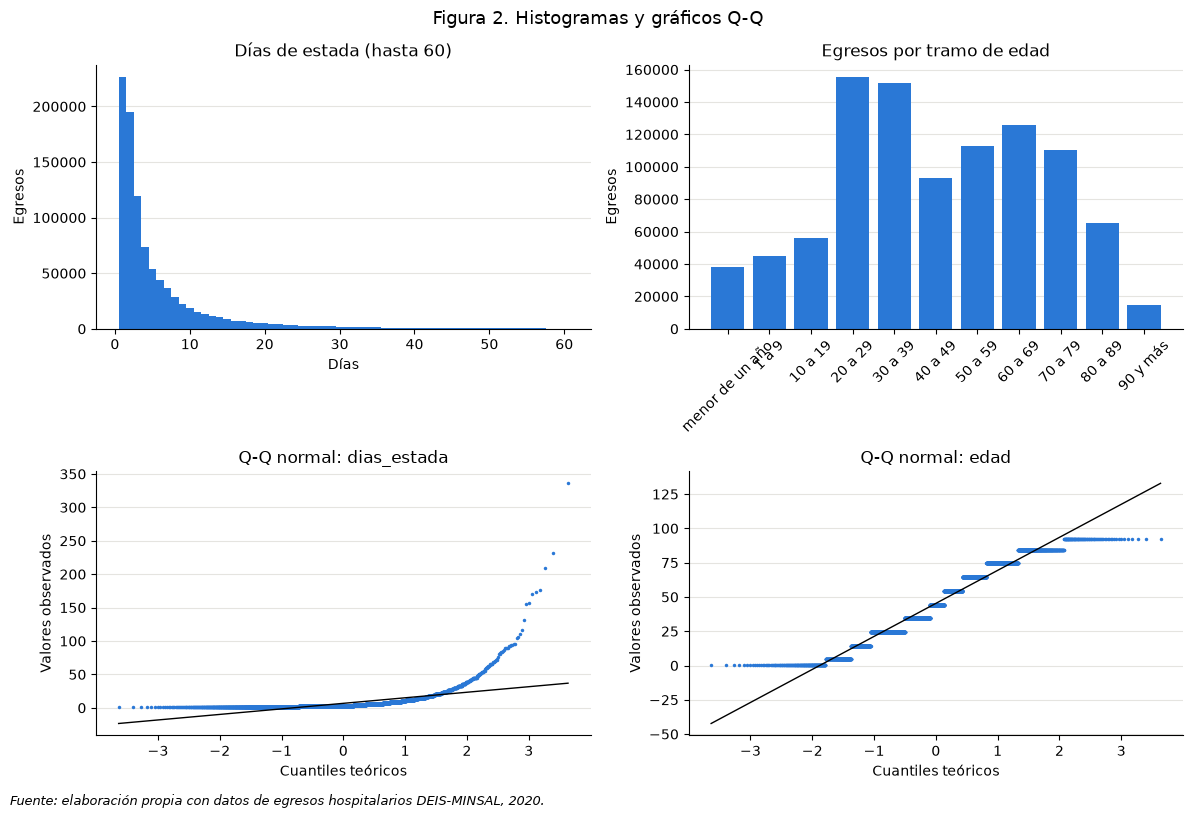

,Variable,Shapiro-Wilk,K-S (Lilliefors),Anderson-Darling,Decisión
0,dias_estada,"W = 0,413; p < 0,001","D = 0,328; p < 0,001","A² = 150.921 (crítico 5 %: 0,752)",Se rechaza H0
1,edad,"W = 0,960; p < 0,001","D = 0,129; p < 0,001","A² = 13.546 (crítico 5 %: 0,752)",Se rechaza H0


In [4]:
def normalidad(nombre):
    x = df[nombre].to_numpy(float)
    sw = stats.shapiro(rng.choice(x, 5000, replace=False))  # Shapiro-Wilk con muestra de 5.000
    d, p_ks = lilliefors(x, dist="norm", pvalmethod="approx")
    ad = stats.anderson(x, dist="norm")
    rechaza = sw.pvalue < ALPHA and p_ks < ALPHA and ad.statistic > ad.critical_values[2]
    return {"Variable": nombre,
            "Shapiro-Wilk": f"W = {num(sw.statistic, 3)}; p {valor_p(sw.pvalue)}",
            "K-S (Lilliefors)": f"D = {num(d, 3)}; p {valor_p(p_ks)}",
            "Anderson-Darling": f"A² = {num(ad.statistic)} (crítico 5 %: {num(ad.critical_values[2], 3)})",
            "Decisión": "Se rechaza H0" if rechaza else "No se rechaza H0"}

fig, ax = plt.subplots(2, 2, figsize=(12, 8))
ax[0, 0].hist(df["dias_estada"], bins=np.arange(0.5, 61.5), color=AZUL)
ax[0, 0].set_title("Días de estada (hasta 60)"); ax[0, 0].set_xlabel("Días"); ax[0, 0].set_ylabel("Egresos")
conteo = df["tramo_edad"].value_counts(sort=False)
ax[0, 1].bar(conteo.index.astype(str), conteo.values, color=AZUL)
ax[0, 1].set_title("Egresos por tramo de edad"); ax[0, 1].set_ylabel("Egresos")
ax[0, 1].tick_params(axis="x", rotation=45)
for a_, var in zip(ax[1], ["dias_estada", "edad"]):
    stats.probplot(rng.choice(df[var].to_numpy(float), 5000, replace=False), plot=a_)
    a_.get_lines()[0].set(marker="o", markersize=2.5, markerfacecolor=AZUL, markeredgecolor="none")
    a_.get_lines()[1].set(color="black", linewidth=1)
    a_.set_title(f"Q-Q normal: {var}"); a_.set_xlabel("Cuantiles teóricos"); a_.set_ylabel("Valores observados")
fig.suptitle("Figura 2. Histogramas y gráficos Q-Q", fontsize=13)
fig.tight_layout(); fuente(fig); plt.show()
pd.DataFrame([normalidad("dias_estada"), normalidad("edad")])

**Resultado:** las tres pruebas rechazan la normalidad en ambas variables (p < 0,001).

- **Días de estada:** muy asimétrica a la derecha. La mitad de las hospitalizaciones dura 3 días o menos y el 90 % dura 15 o menos, pero hay estadías de hasta 365 días.
- **Edad:** tiene dos picos (20 a 39 años, por los partos, y 60 a 69 años) y viene en tramos, lo que se ve como escalones en el gráfico Q-Q.

**Consecuencia:** desde aquí se usan pruebas no paramétricas (Spearman, Mann-Whitney U y Kruskal-Wallis). Para la regresión lineal del Avance 2 se usará el logaritmo de los días.

### 5.2 Numérica vs. numérica: edad y días de estada

Como ninguna de las dos es normal, se usa **Spearman** en vez de Pearson.

- **H₀:** ρ = 0 (no hay relación monótona entre edad y días de estada).
- **H₁:** ρ ≠ 0.

Spearman: rho = 0,250 | p < 0,001 | n = 968.098 | Se rechaza H0


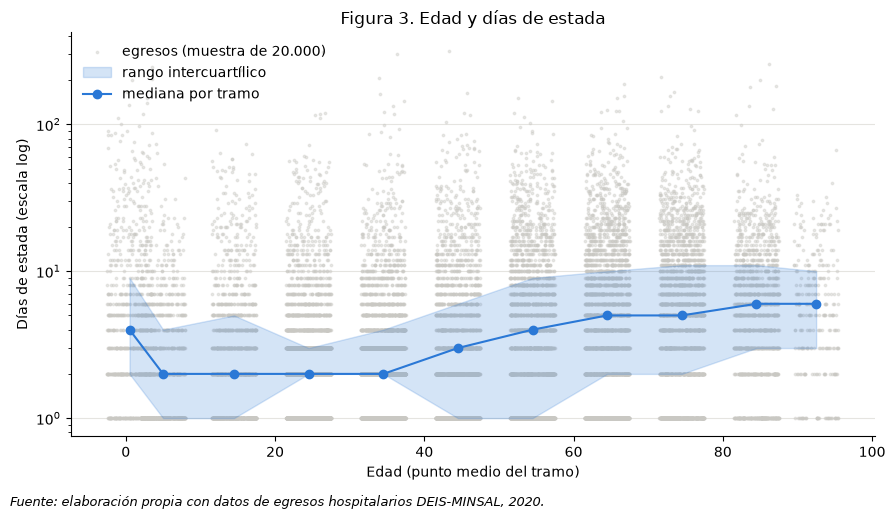

In [5]:
rho, p = stats.spearmanr(df["edad"], df["dias_estada"])
print(f"Spearman: rho = {num(rho, 3)} | p {valor_p(p)} | n = {miles(len(df))} | {decision(p)}")

cuartiles = df.groupby("edad")["dias_estada"].quantile([0.25, 0.5, 0.75]).unstack()
muestra = df.sample(20000, random_state=2026)
fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(muestra["edad"] + rng.uniform(-3, 3, len(muestra)), muestra["dias_estada"], s=3, color=GRIS,
           alpha=0.4, label="egresos (muestra de 20.000)")
ax.fill_between(cuartiles.index, cuartiles[0.25], cuartiles[0.75], color=AZUL, alpha=0.2,
                label="rango intercuartílico")
ax.plot(cuartiles.index, cuartiles[0.5], "-o", color=AZUL, label="mediana por tramo")
ax.set_yscale("log"); ax.set_xlabel("Edad (punto medio del tramo)"); ax.set_ylabel("Días de estada (escala log)")
ax.set_title("Figura 3. Edad y días de estada"); ax.legend(frameon=False)
fig.tight_layout(); fuente(fig); plt.show()

| Coeficiente | Valor | Valor-p | n | Decisión | Efecto |
|---|---|---|---|---|---|
| ρ de Spearman | 0,250 | < 0,001 | 968.098 | Se rechaza H₀ | Pequeño |

**Interpretación:** a mayor edad, la hospitalización tiende a durar más, pero la relación es débil. La mediana sube de 2 días (1 a 39 años) a 5 días (60 a 79) y a 6 días (80 o más). Los menores de un año rompen el patrón, con una mediana de 4 días (Figura 3). Por eso en el modelo conviene incluir la edad con un término cuadrático o por tramos.

### 5.3 Numérica vs. categórica: días de estada según cada factor

Como los días de estada no son normales, se usan las pruebas no paramétricas en vez de t de Student y ANOVA:

- **Mann-Whitney U** para los factores con dos grupos (sexo, nacionalidad, etnia, cirugía, establecimiento). Efecto: correlación biserial *r* (si es positiva, el primer grupo tiene estadías más largas).
- **Kruskal-Wallis** para los factores con más grupos (capítulo CIE-10 y región). Efecto: ε². Si sale significativo, la prueba post-hoc de **Dunn** (con corrección de Holm) indica qué pares de grupos difieren.

Para cada factor:

- **H₀:** los días de estada se distribuyen igual en todos los grupos.
- **H₁:** al menos un grupo tiene una distribución distinta.

In [6]:
def tamano(valor, umbrales):
    valor = abs(valor)
    return "despreciable" if valor < umbrales[0] else "pequeño" if valor < umbrales[1] else \
        "mediano" if valor < umbrales[2] else "grande"

def mann_whitney(var):
    a, b = sorted(df[var].unique())
    xa = df.loc[df[var] == a, "dias_estada"]; xb = df.loc[df[var] == b, "dias_estada"]
    u = stats.mannwhitneyu(xa, xb)
    r = 2 * u.statistic / (len(xa) * len(xb)) - 1  # correlación biserial de rangos
    return {"Variable": var, "Grupos": f"{a} / {b}", "Mediana (días)": f"{num(xa.median())} / {num(xb.median())}",
            "Prueba": "Mann-Whitney U", "Estadístico": f"U = {num(u.statistic / 1e9, 1)} × 10⁹", "Valor-p": valor_p(u.pvalue),
            "Efecto": f"r = {num(r, 2)} ({tamano(r, (0.1, 0.3, 0.5))})", "Decisión": decision(u.pvalue)}

def kruskal(var):
    grupos = [g.to_numpy() for _, g in df.groupby(var)["dias_estada"]]
    h = stats.kruskal(*grupos)
    eps2 = h.statistic / (len(df) - 1)
    med = df.groupby(var)["dias_estada"].median()
    return {"Variable": var, "Grupos": f"{len(grupos)} grupos", "Mediana (días)": f"{num(med.min())} a {num(med.max())}",
            "Prueba": "Kruskal-Wallis", "Estadístico": f"H = {num(h.statistic)} (gl = {len(grupos) - 1})",
            "Valor-p": valor_p(h.pvalue), "Efecto": f"ε² = {num(eps2, 3)} ({tamano(eps2, (0.01, 0.06, 0.14))})",
            "Decisión": decision(h.pvalue)}

# r > 0: el primer grupo tiene estadías más largas; r < 0: el segundo
BINARIAS = ["sexo", "nacionalidad", "etnia", "cirugia", "establecimiento"]
VARIAS = ["capitulo", "region"]
tabla_53 = pd.DataFrame([mann_whitney(v) for v in BINARIAS] + [kruskal(v) for v in VARIAS])
tabla_53

,Variable,Grupos,Mediana (días),Prueba,Estadístico,Valor-p,Efecto,Decisión
0,sexo,Hombre / Mujer,4 / 3,Mann-Whitney U,"U = 128,2 × 10⁹","< 0,001","r = 0,14 (pequeño)",Se rechaza H0
1,nacionalidad,Chilena / Extranjera,3 / 3,Mann-Whitney U,"U = 18,9 × 10⁹","< 0,001","r = 0,06 (despreciable)",Se rechaza H0
2,etnia,No / Sí,3 / 3,Mann-Whitney U,"U = 9,8 × 10⁹","< 0,001","r = -0,02 (despreciable)",Se rechaza H0
3,cirugia,No / Sí,4 / 2,Mann-Whitney U,"U = 134,3 × 10⁹","< 0,001","r = 0,22 (pequeño)",Se rechaza H0
4,establecimiento,No SNSS / Público (SNSS),2 / 3,Mann-Whitney U,"U = 43,6 × 10⁹","< 0,001","r = -0,37 (mediano)",Se rechaza H0
5,capitulo,21 grupos,1 a 9,Kruskal-Wallis,H = 116.411 (gl = 20),"< 0,001","ε² = 0,120 (mediano)",Se rechaza H0
6,region,16 grupos,2 a 4,Kruskal-Wallis,H = 2.260 (gl = 15),"< 0,001","ε² = 0,002 (despreciable)",Se rechaza H0


In [7]:
def dunn(var):
    """Post-hoc de Dunn: compara cada par de grupos y corrige los valores-p con Holm."""
    rangos = df["dias_estada"].rank()
    n = len(df)
    empates = df["dias_estada"].value_counts().to_numpy(float)
    varianza = n * (n + 1) / 12 - (empates**3 - empates).sum() / (12 * (n - 1))
    g = rangos.groupby(df[var]).agg(["mean", "size"])
    pares = []
    for i, a in enumerate(g.index):
        for b in g.index[i + 1:]:
            z = (g.loc[a, "mean"] - g.loc[b, "mean"]) / np.sqrt(varianza * (1 / g.loc[a, "size"] + 1 / g.loc[b, "size"]))
            pares.append((a, b, 2 * stats.norm.sf(abs(z))))
    res = pd.DataFrame(pares, columns=["Grupo A", "Grupo B", "p"])
    res["p (Holm)"] = multipletests(res["p"], method="holm")[1]
    print(f"{var}: {(res['p (Holm)'] < ALPHA).sum()} de {len(res)} pares difieren (p Holm < 0,05)")
    return res

dunn_cap = dunn("capitulo")
dunn_reg = dunn("region")

capitulo: 201 de 210 pares difieren (p Holm < 0,05)


region: 102 de 120 pares difieren (p Holm < 0,05)


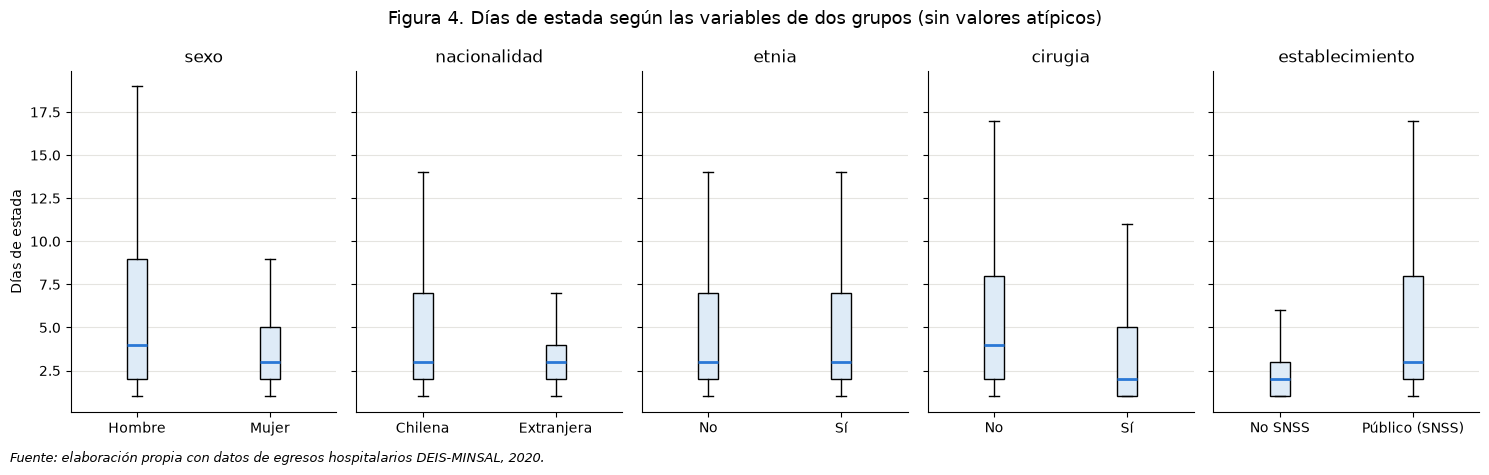

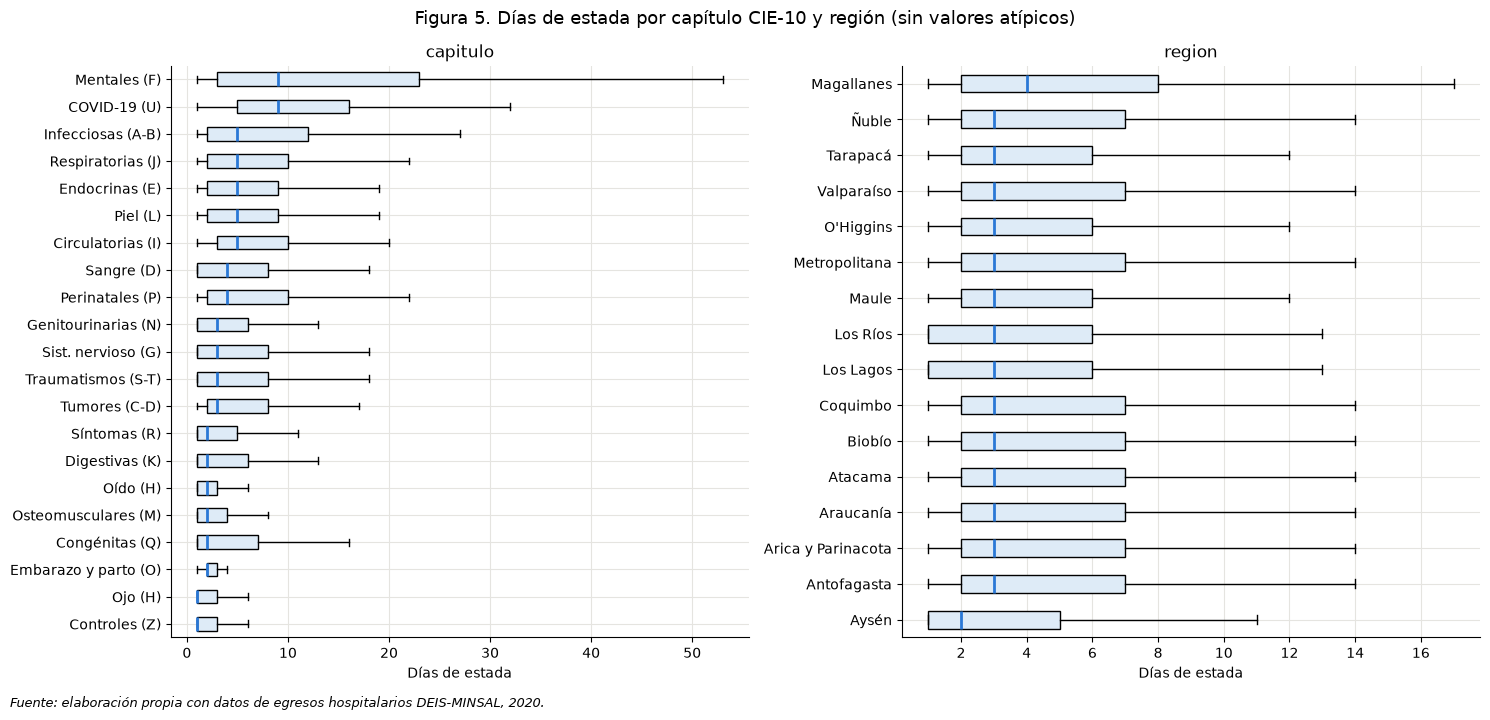

In [8]:
fig, ax = plt.subplots(1, 5, figsize=(15, 4.5), sharey=True)
for a_, var in zip(ax, BINARIAS):
    grupos = sorted(df[var].unique())
    a_.boxplot([df.loc[df[var] == g, "dias_estada"] for g in grupos], tick_labels=grupos, showfliers=False,
               patch_artist=True, boxprops=dict(facecolor="#deebf7"), medianprops=dict(color=AZUL, linewidth=2))
    a_.set_title(var)
ax[0].set_ylabel("Días de estada")
fig.suptitle("Figura 4. Días de estada según las variables de dos grupos (sin valores atípicos)", fontsize=13)
fig.tight_layout(); fuente(fig); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(15, 7))
for a_, var in zip(ax, VARIAS):
    orden = df.groupby(var)["dias_estada"].median().sort_values().index
    a_.boxplot([df.loc[df[var] == g, "dias_estada"] for g in orden], tick_labels=orden, vert=False, showfliers=False,
               patch_artist=True, boxprops=dict(facecolor="#deebf7"), medianprops=dict(color=AZUL, linewidth=2))
    a_.set_title(var); a_.set_xlabel("Días de estada"); a_.grid(axis="x", color="#e5e4e0")
fig.suptitle("Figura 5. Días de estada por capítulo CIE-10 y región (sin valores atípicos)", fontsize=13)
fig.tight_layout(); fuente(fig); plt.show()

**Interpretación** (todas las pruebas rechazan H₀, así que lo importante es el tamaño del efecto):

- **Tipo de establecimiento (efecto mediano, r = −0,37):** las hospitalizaciones en establecimientos públicos del SNSS duran más que en los no SNSS (mediana de 3 y 2 días). La diferencia es mayor de lo que sugieren las medianas, porque los no SNSS casi no tienen estadías largas (Figura 4).
- **Capítulo CIE-10 (efecto mediano, ε² = 0,12):** es el factor que más separa la duración. Trastornos mentales y COVID-19 tienen una mediana de 9 días; partos, ojo y controles, de 1 a 2 días (Figura 5). Según Dunn, 201 de los 210 pares de capítulos difieren.
- **Cirugía (pequeño, r = 0,22):** sin cirugía la estadía es más larga (mediana de 4 y 2 días). Muchas cirugías son programadas y de recuperación rápida.
- **Sexo (pequeño, r = 0,14):** los hombres tienen un día más de mediana (4 y 3 días). Parte de esto se explica por los partos, que son de corta duración y solo afectan a mujeres.
- **Nacionalidad, etnia y región (despreciables):** son significativas solo por el tamaño de la muestra. En la región, las medianas van de 2 días (Aysén) a 4 (Magallanes), y aunque Dunn encuentra 102 de 120 pares distintos, ε² = 0,002 indica que la región casi no explica la duración.

### 5.4 Categórica vs. categórica: estadía prolongada según cada factor

Se usa **chi-cuadrado de independencia** entre cada factor y la estadía prolongada (para la edad se usan sus 11 tramos). La fuerza de la asociación se mide con la **V de Cramér**.

- **H₀:** el factor y la estadía prolongada son independientes.
- **H₁:** el factor y la estadía prolongada están asociados.

La prueba exige frecuencias esperadas ≥ 5 en todas las celdas. Si no se cumpliera en una tabla 2 × 2, se usaría el test exacto de Fisher.

In [9]:
def chi_cuadrado(var):
    tabla = pd.crosstab(df[var], df["prolongada"])
    chi2, p, gl, esperadas = stats.chi2_contingency(tabla)
    v = np.sqrt(chi2 / (tabla.to_numpy().sum() * (min(tabla.shape) - 1)))
    pct = 100 * tabla["Sí"] / tabla.sum(axis=1)
    return {"Variable": var, "% prolongadas": f"{num(pct.min(), 1)} % ({pct.idxmin()}) a {num(pct.max(), 1)} % ({pct.idxmax()})",
            "Chi²": num(chi2), "gl": gl, "Valor-p": valor_p(p),
            "V de Cramér": f"{num(v, 3)} ({tamano(v, (0.1, 0.3, 0.5))})",
            "Mín. frec. esperada": num(esperadas.min()), "Decisión": decision(p)}

CATEGORICAS = ["tramo_edad", "sexo", "nacionalidad", "etnia", "capitulo", "cirugia", "establecimiento", "region"]
tabla_54 = pd.DataFrame([chi_cuadrado(v) for v in CATEGORICAS])
tabla_54

,Variable,% prolongadas,Chi²,gl,Valor-p,V de Cramér,Mín. frec. esperada,Decisión
0,tramo_edad,"3,5 % (20 a 29) a 15,4 % (menor de un año)",26.265,10,"< 0,001","0,165 (pequeño)",1.408,Se rechaza H0
1,sexo,"6,9 % (Mujer) a 13,1 % (Hombre)",10.332,1,"< 0,001","0,103 (pequeño)",36.376,Se rechaza H0
2,nacionalidad,"5,7 % (Extranjera) a 9,5 % (Chilena)",642,1,"< 0,001","0,026 (despreciable)",3.599,Se rechaza H0
3,etnia,"8,6 % (Sí) a 9,4 % (No)",14,1,"< 0,001","0,004 (despreciable)",1.987,Se rechaza H0
4,capitulo,"0,9 % (Embarazo y parto (O)) a 35,6 % (Mentale...",60.840,20,"< 0,001","0,251 (pequeño)",175,Se rechaza H0
5,cirugia,"7,4 % (Sí) a 10,6 % (No)",2.749,1,"< 0,001","0,053 (despreciable)",34.007,Se rechaza H0
6,establecimiento,"4,2 % (No SNSS) a 10,6 % (Público (SNSS))",6.897,1,"< 0,001","0,084 (despreciable)",16.504,Se rechaza H0
7,region,"6,6 % (Aysén) a 10,9 % (Metropolitana)",2.343,15,"< 0,001","0,049 (despreciable)",674,Se rechaza H0


In [10]:
# Ejemplo de tabla de contingencia: tipo de establecimiento vs estadía prolongada
tabla = pd.crosstab(df["establecimiento"], df["prolongada"], margins=True, margins_name="Total")
tabla["% prolongadas"] = 100 * tabla["Sí"] / tabla["Total"]
tabla.map(lambda x: num(x, 1) if isinstance(x, float) else num(x))

prolongada,No,Sí,Total,% prolongadas
establecimiento,,,,
No SNSS,168.437,7.316,175.753,"4,2"
Público (SNSS),708.752,83.593,792.345,"10,6"
Total,877.189,90.909,968.098,"9,4"


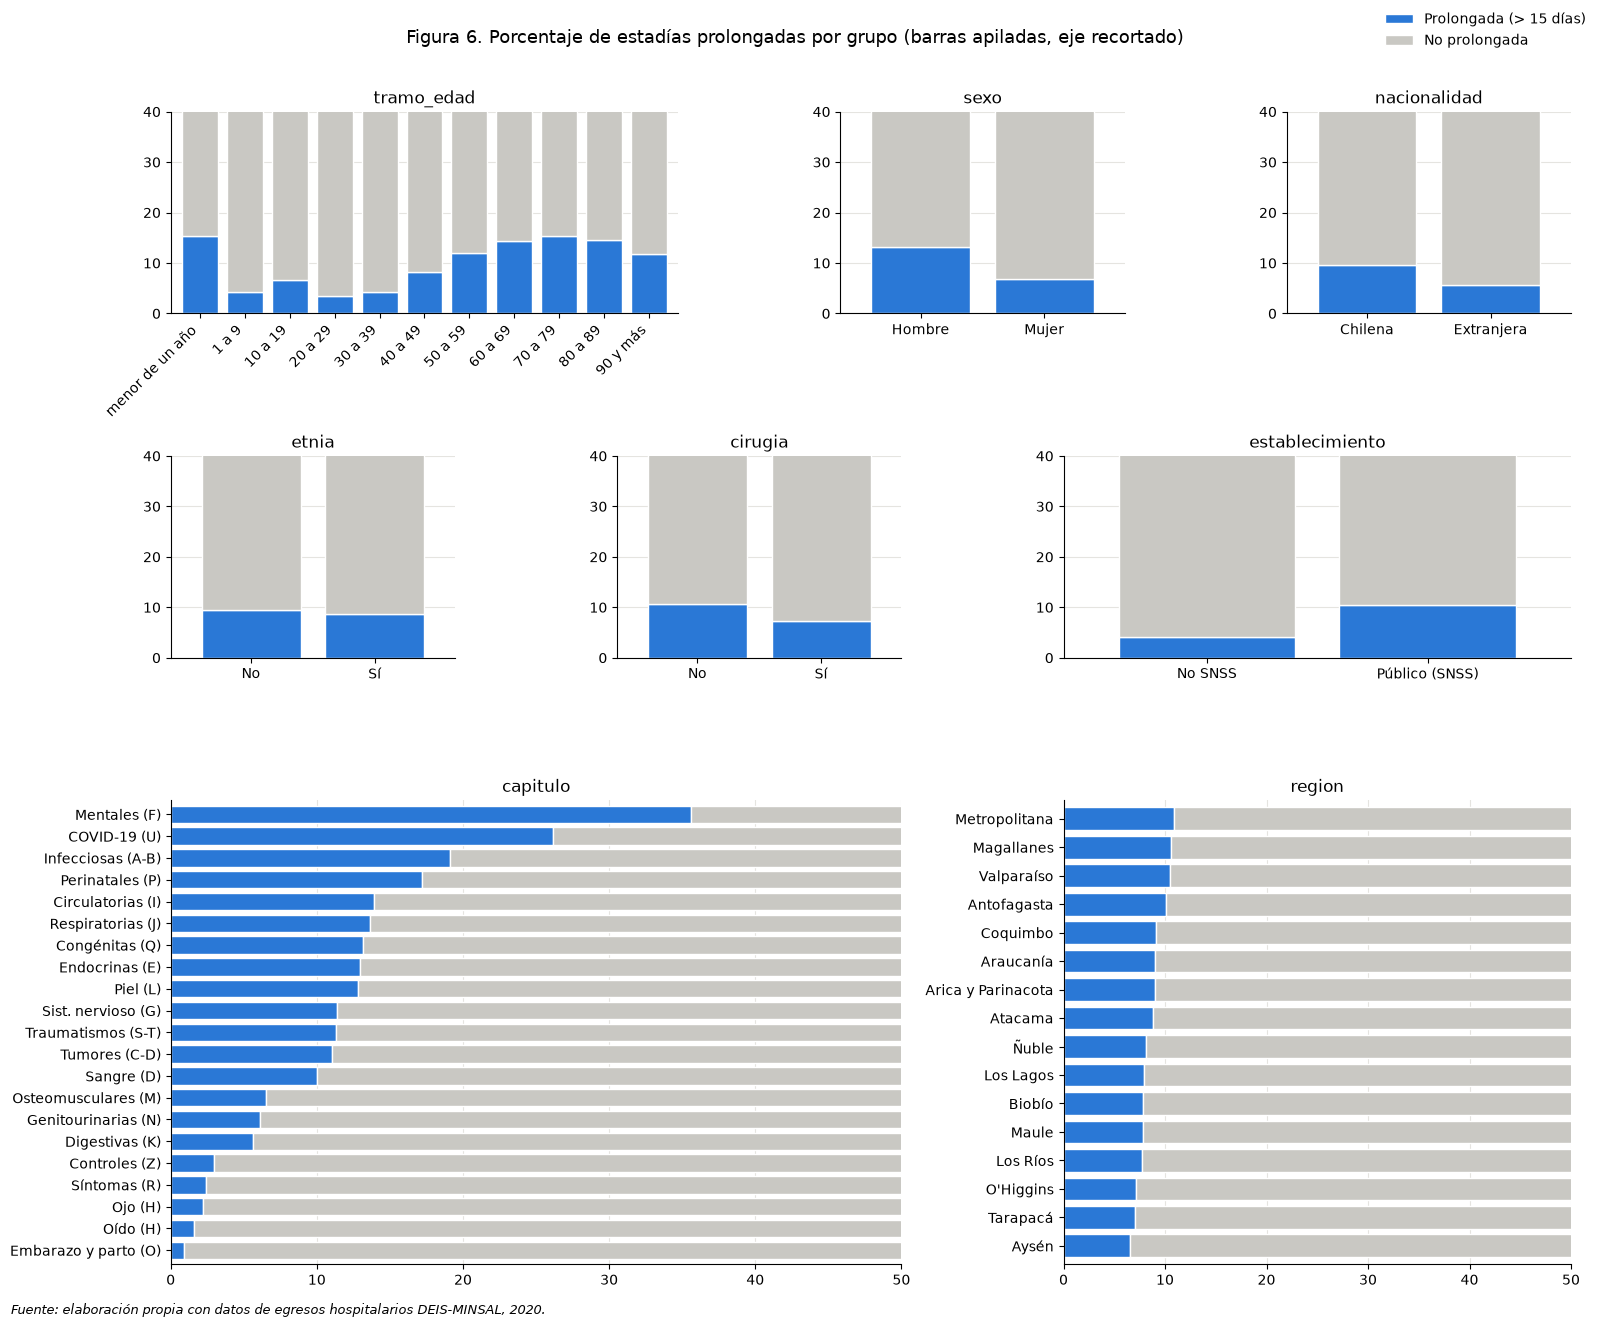

In [11]:
fig = plt.figure(figsize=(16, 13))
grid = fig.add_gridspec(3, 7, height_ratios=[1, 1, 2.3])
pequenas = ["tramo_edad", "sexo", "nacionalidad", "etnia", "cirugia", "establecimiento"]
posiciones = [grid[0, 0:3], grid[0, 3:5], grid[0, 5:7], grid[1, 0:2], grid[1, 2:4], grid[1, 4:7]]
for pos, var in zip(posiciones + [grid[2, 0:4], grid[2, 4:7]], pequenas + ["capitulo", "region"]):
    a_ = fig.add_subplot(pos)
    pct = pd.crosstab(df[var], df["prolongada"], normalize="index")[["Sí", "No"]] * 100
    horizontal = var in ("capitulo", "region")
    if horizontal:
        pct = pct.sort_values("Sí")
    pct.plot(kind="barh" if horizontal else "bar", stacked=True, ax=a_, color=[AZUL, GRIS], width=0.8,
             legend=False, edgecolor="white")
    a_.set_title(var); a_.set_xlabel(""); a_.set_ylabel("")
    if not horizontal:
        plt.setp(a_.get_xticklabels(), rotation=45 if var == "tramo_edad" else 0, ha="right" if var == "tramo_edad" else "center")
        a_.set_ylim(0, 40)
    else:
        a_.set_xlim(0, 50); a_.grid(axis="x", color="#e5e4e0")
fig.legend(["Prolongada (> 15 días)", "No prolongada"], loc="upper right", frameon=False)
fig.suptitle("Figura 6. Porcentaje de estadías prolongadas por grupo (barras apiladas, eje recortado)", fontsize=13)
fig.tight_layout(rect=(0, 0, 1, 0.97)); fuente(fig); plt.show()

Todas las frecuencias esperadas superan 5 (la menor es 175), así que el chi-cuadrado es válido y no se necesita el test de Fisher.

**Interpretación** (todas rechazan H₀; se ordena por la V de Cramér):

- **Capítulo CIE-10 (V = 0,25, pequeño):** el factor más asociado. Las estadías prolongadas van de 0,9 % en partos a 35,6 % en trastornos mentales; COVID-19 llega a 26,2 % (Figura 6).
- **Tramo de edad (V = 0,17, pequeño):** forma de U. Es 15,4 % en menores de un año, baja a 3,5 % entre 20 y 29 años y vuelve a 15,4 % entre 70 y 79. Spearman (5.2) no capta esta forma.
- **Sexo (V = 0,10, pequeño):** 13,1 % en hombres y 6,9 % en mujeres.
- **Establecimiento (V = 0,08, en el límite):** 10,6 % en públicos SNSS y 4,2 % en no SNSS; el riesgo es 2,5 veces mayor en los públicos.
- **Cirugía, región, nacionalidad y etnia (despreciables):** diferencias de pocos puntos porcentuales, sin relevancia práctica por sí solas.

Que un factor tenga efecto despreciable por sí solo no impide incluirlo en el modelo: la regresión múltiple mostrará si aporta algo al controlar por los demás.

#### Relación entre los predictores

Para la regresión múltiple también importa que los predictores no repitan la misma información, porque eso vuelve inestables los coeficientes (multicolinealidad). La Figura 7 muestra la V de Cramér entre cada par de predictores. Se presenta como apoyo descriptivo: con este n, todos los pares resultan significativos, así que se mira solo el tamaño.

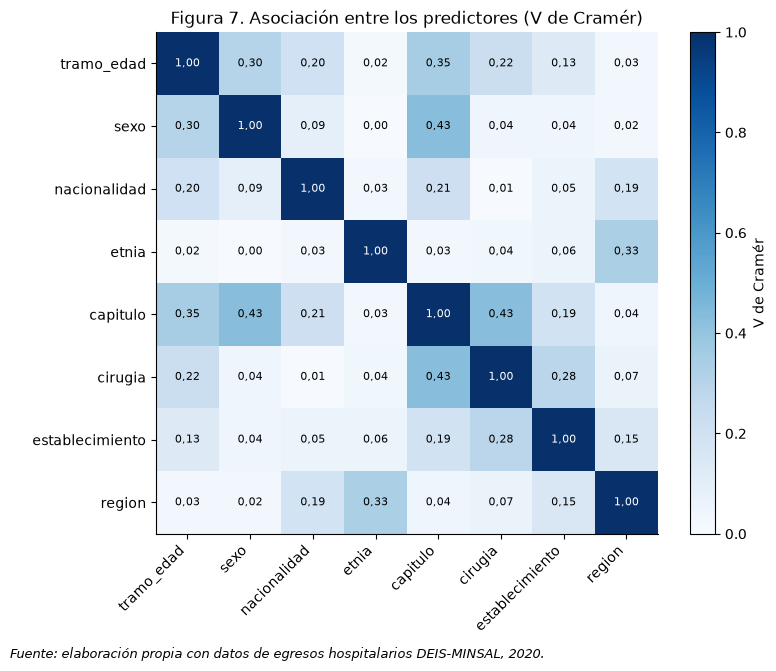

Pares de predictores más asociados:
  capitulo - cirugia: V = 0,43
  sexo - capitulo: V = 0,43
  tramo_edad - capitulo: V = 0,35


In [12]:
PREDICTORES = ["tramo_edad", "sexo", "nacionalidad", "etnia", "capitulo", "cirugia", "establecimiento", "region"]

def v_cramer(a, b):
    tabla = pd.crosstab(df[a], df[b])
    chi2 = stats.chi2_contingency(tabla)[0]
    return np.sqrt(chi2 / (tabla.to_numpy().sum() * (min(tabla.shape) - 1)))

matriz = pd.DataFrame(1.0, index=PREDICTORES, columns=PREDICTORES)
for i, a in enumerate(PREDICTORES):
    for b in PREDICTORES[i + 1:]:
        matriz.loc[a, b] = matriz.loc[b, a] = v_cramer(a, b)

fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(matriz, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(PREDICTORES)), PREDICTORES, rotation=45, ha="right"); ax.set_yticks(range(len(PREDICTORES)), PREDICTORES)
ax.grid(False)
for i in range(len(PREDICTORES)):
    for j in range(len(PREDICTORES)):
        ax.text(j, i, num(matriz.iloc[i, j], 2), ha="center", va="center", fontsize=8,
                color="white" if matriz.iloc[i, j] > 0.5 else "black")
fig.colorbar(im, ax=ax, label="V de Cramér")
ax.set_title("Figura 7. Asociación entre los predictores (V de Cramér)")
fig.tight_layout(); fuente(fig); plt.show()
pares = matriz.where(np.triu(np.ones(matriz.shape, bool), k=1)).stack().sort_values(ascending=False)
print("Pares de predictores más asociados:")
for (a, b), v in pares.head(3).items():
    print(f"  {a} - {b}: V = {num(v, 2)}")

**Interpretación:** ningún par de predictores supera V = 0,43 (capítulo con cirugía y capítulo con sexo, este último por los partos). Ningún predictor repite a otro, así que pueden entrar juntos en la regresión múltiple. Igual se revisará el VIF en el Avance 2. La única redundancia encontrada fue la causa externa (`DIAG2`), que se descartó en la sección 3 por repetir el capítulo de traumatismos.

### 5.5 Tabla resumen

| Variable 1 | Variable 2 | Test aplicado | Valor-p | Efecto | Conclusión |
|---|---|---|---|---|---|
| Días de estada | Normal | Shapiro-Wilk, K-S (Lilliefors), Anderson-Darling | < 0,001 | | No es normal: pruebas no paramétricas |
| Edad | Normal | Shapiro-Wilk, K-S (Lilliefors), Anderson-Darling | < 0,001 | | No es normal: pruebas no paramétricas |
| Edad | Días de estada | Spearman | < 0,001 | ρ = 0,25 (pequeño) | Más edad, estadías algo más largas |
| Sexo | Días de estada | Mann-Whitney U | < 0,001 | r = 0,14 (pequeño) | Hombres con estadías más largas |
| Nacionalidad | Días de estada | Mann-Whitney U | < 0,001 | r = 0,06 (despreciable) | Sin diferencia relevante |
| Etnia | Días de estada | Mann-Whitney U | < 0,001 | r = −0,02 (despreciable) | Sin diferencia relevante |
| Cirugía | Días de estada | Mann-Whitney U | < 0,001 | r = 0,22 (pequeño) | Sin cirugía, estadías más largas |
| Establecimiento | Días de estada | Mann-Whitney U | < 0,001 | r = −0,37 (mediano) | Públicos SNSS con estadías más largas |
| Capítulo CIE-10 | Días de estada | Kruskal-Wallis + Dunn | < 0,001 | ε² = 0,12 (mediano) | Mediana de 1 a 9 días según capítulo |
| Región | Días de estada | Kruskal-Wallis + Dunn | < 0,001 | ε² = 0,002 (despreciable) | Sin diferencia relevante |
| Tramo de edad | Estadía prolongada | Chi-cuadrado | < 0,001 | V = 0,17 (pequeño) | Forma de U: más en menores de un año y mayores |
| Sexo | Estadía prolongada | Chi-cuadrado | < 0,001 | V = 0,10 (pequeño) | 13,1 % hombres y 6,9 % mujeres |
| Nacionalidad | Estadía prolongada | Chi-cuadrado | < 0,001 | V = 0,03 (despreciable) | Sin diferencia relevante |
| Etnia | Estadía prolongada | Chi-cuadrado | < 0,001 | V = 0,004 (despreciable) | Sin diferencia relevante |
| Capítulo CIE-10 | Estadía prolongada | Chi-cuadrado | < 0,001 | V = 0,25 (pequeño) | De 0,9 % (partos) a 35,6 % (mentales) |
| Cirugía | Estadía prolongada | Chi-cuadrado | < 0,001 | V = 0,05 (despreciable) | Sin diferencia relevante |
| Establecimiento | Estadía prolongada | Chi-cuadrado | < 0,001 | V = 0,08 (despreciable) | 10,6 % públicos y 4,2 % no SNSS |
| Región | Estadía prolongada | Chi-cuadrado | < 0,001 | V = 0,05 (despreciable) | Sin diferencia relevante |

### Conclusión del Avance 1

Las 16 pruebas de asociación rechazan H₀, así que se rechaza la hipótesis nula general. Mirando el tamaño del efecto:

- **H1a (clínicos):** se confirma. El capítulo CIE-10 es el factor más fuerte en las dos respuestas; la cirugía influye en los días, pero poco en la estadía prolongada.
- **H1b (demográficos):** se confirma para edad y sexo, con efectos pequeños. La edad sigue la dirección esperada, salvo en los menores de un año. Nacionalidad y etnia no tienen efecto relevante.
- **H1c (sistema de salud):** se confirma para el tipo de establecimiento, que tiene el segundo efecto más grande sobre los días. La región no tiene efecto relevante.

Estos resultados son asociaciones de a pares. El Avance 2 usará regresiones múltiples para ver qué factores siguen importando cuando se consideran todos juntos, por ejemplo si la diferencia entre hombres y mujeres se mantiene al controlar por diagnóstico.

## Referencias

1. Cohen, J. (1988). *Statistical power analysis for the behavioral sciences* (2.ª ed.). Lawrence Erlbaum Associates.
2. Fetter, R. B., Shin, Y., Freeman, J. L., Averill, R. F., & Thompson, J. D. (1980). Case mix definition by diagnosis-related groups. *Medical Care, 18*(2 Suppl.), 1–53.
3. Freitas, A., Silva-Costa, T., Lopes, F., Garcia-Lema, I., Teixeira-Pinto, A., Brazdil, P., & Costa-Pereira, A. (2012). Factors influencing hospital high length of stay outliers. *BMC Health Services Research, 12*, 265. https://doi.org/10.1186/1472-6963-12-265
4. Lequertier, V., Wang, T., Fondrevelle, J., Augusto, V., & Duclos, A. (2021). Hospital length of stay prediction methods: A systematic review. *Medical Care, 59*(10), 929–938. https://doi.org/10.1097/MLR.0000000000001596
5. Lin, M., Lucas, H. C., & Shmueli, G. (2013). Too big to fail: Large samples and the p-value problem. *Information Systems Research, 24*(4), 906–917. https://doi.org/10.1287/isre.2013.0480
6. Olivares-Tirado, P. (2020). *Hospitalización social en adultos mayores en el sistema de salud de Chile* [Documento de trabajo]. Superintendencia de Salud. https://www.superdesalud.gob.cl/biblioteca-digital/hospitalizacion-social-en-adultos-mayores-en-el-sistema-de-salud-de-chile/